In [4]:
# !pip install medmnist

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import medmnist
from medmnist import INFO

In [6]:
info = INFO["pneumoniamnist"]
print(info)

{'python_class': 'PneumoniaMNIST', 'description': 'The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.', 'url': 'https://zenodo.org/records/10519652/files/pneumoniamnist.npz?download=1', 'MD5': '28209eda62fecd6e6a2d98b1501bb15f', 'url_64': 'https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1', 'MD5_64': '8f4eceb4ccffa70c672198ea285246c6', 'url_128': 'https://zenodo.org/records/10519652/files/pneumoniamnist_128.npz?download=1', 'MD5_128': '05b46931834c231683c68f40c47b2971', 'url_224': 'https://zenodo.org/records/10519652/files/pneumoniamnist_224.npz?download=1', 'MD5_224': 'd6a3c71de1b945ea11211b

In [7]:
print("Dataset:", info["python_class"])
print("Task:", info["task"])
print("Number of classes:", info["label"])
print("Number of channels:", info["n_channels"])
print("Number of samples:", info["n_samples"])

Dataset: PneumoniaMNIST
Task: binary-class
Number of classes: {'0': 'normal', '1': 'pneumonia'}
Number of channels: 1
Number of samples: {'train': 4708, 'val': 524, 'test': 624}


## Load Dataset

In [8]:
from medmnist.dataset import PneumoniaMNIST

In [13]:
train_dataset = PneumoniaMNIST(
    split="train",
    download=True,
)

100%|█████████████████████████████████████████████████████████████████████████████| 4.17M/4.17M [00:52<00:00, 79.9kB/s]


In [15]:
val_dataset = PneumoniaMNIST(
    split="val",
    download=True
)

In [16]:
test_dataset = PneumoniaMNIST(
    split="test",
    download=True
)

In [17]:
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 4708
Validation samples: 524
Test samples: 624


## Image

In [20]:
image, label = train_dataset[0]

In [22]:
type(image)

PIL.Image.Image

In [23]:
print("Image shape:", image.size)
print("Label:", label)

Image shape: (28, 28)
Label: [1]


In [24]:
image_np = np.array(image)

print(image_np.shape)

(28, 28)


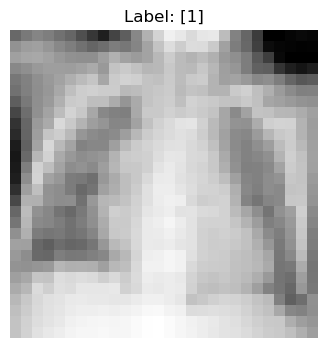

In [25]:
plt.figure(figsize=(4, 4))

plt.imshow(image_np, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")

plt.show()

## Analyze fisrt 10 images

In [26]:
for i in range(10):
    image, label = train_dataset[i]
    print(i, label)

0 [1]
1 [1]
2 [1]
3 [1]
4 [1]
5 [0]
6 [1]
7 [0]
8 [1]
9 [1]


## Check class distribution

In [31]:
train_dataset.labels

array([[1],
       [1],
       [1],
       ...,
       [1],
       [0],
       [1]], dtype=uint8)

In [32]:
train_labels = np.array(train_dataset.labels).flatten()
train_labels

array([1, 1, 1, ..., 1, 0, 1], dtype=uint8)

In [28]:
unique, counts = np.unique(train_labels, return_counts=True)

for label, count in zip(unique, counts):
    print(f"Class {label}: {count}")

Class 0: 1214
Class 1: 3494


In [33]:
class_counts = pd.Series(train_labels).value_counts().sort_index()

class_percentages = class_counts / len(train_labels) * 100

print(class_counts)
print()
print(class_percentages)

0    1214
1    3494
Name: count, dtype: int64

0    25.785896
1    74.214104
Name: count, dtype: float64


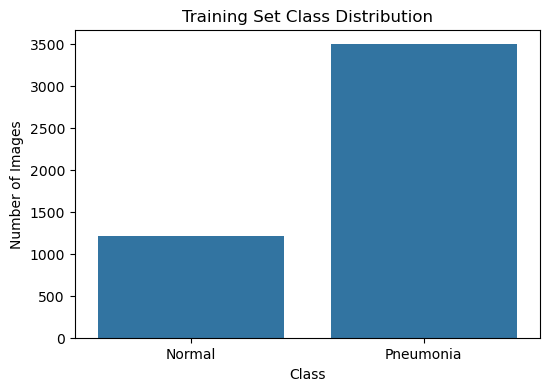

In [35]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x=["Normal", "Pneumonia"],
    y=class_counts.values
)

plt.title("Training Set Class Distribution")
plt.ylabel("Number of Images")
plt.xlabel("Class")

plt.savefig("../plots/training_set_class_distribution.png")
plt.show()

## Normal and Pneumonia Together

In [36]:
normal_index = np.where(train_labels == 0)[0][0]
pneumonia_index = np.where(train_labels == 1)[0][0]

normal_image, _ = train_dataset[normal_index]
pneumonia_image, _ = train_dataset[pneumonia_index]

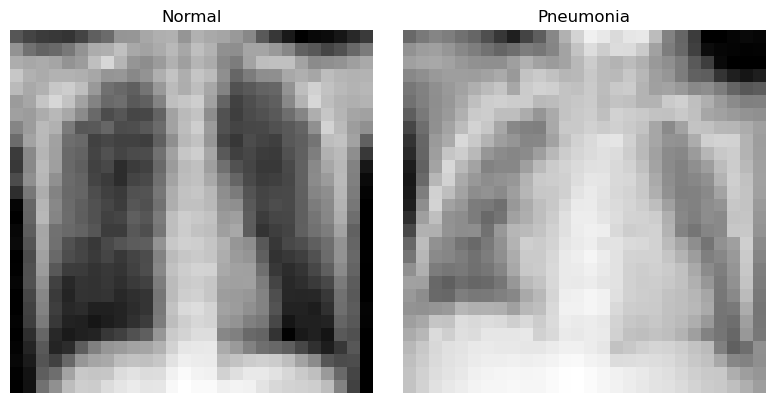

In [37]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.array(normal_image), cmap="gray")
plt.title("Normal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.array(pneumonia_image), cmap="gray")
plt.title("Pneumonia")
plt.axis("off")

plt.savefig("../plots/normal_and_pneumonia.png")
plt.tight_layout()
plt.show()